# ROBT 407 Homework 2, notebook part

Run with Restart Kernel and Run All. Every part sets its own generator from `SEED = 407`.

In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import KFold, train_test_split
from sklearn.svm import SVC

In [38]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

A.1(d) Linear regression with a noisy target

In [39]:
rng = np.random.default_rng(SEED)
d, sigma = 8, 0.1
Ns = [10, 20, 50, 100, 500]
R, N_test = 500, 1000

w_f = rng.standard_normal(d+1)

def make_data(N, rng):
    X = rng.standard_normal((N, d))
    X = add_bias(X)
    
    noise = sigma * rng.standard_normal(N)
    
    y = X @ w_f + noise
    return X, y

Ein_avg, Eout_avg = [], []
for N in Ns:
    ein, eout = [], []
    for r in range(R):
        X, y = make_data(N, rng)
        w_lin = np.linalg.lstsq(X, y, rcond=None)[0]
        ein.append(mse(y, X @ w_lin))
        
        X_test, y_test = make_data(N_test, rng)
        eout.append(mse(y_test, X_test @ w_lin))
    Ein_avg.append(np.mean(ein))
    Eout_avg.append(np.mean(eout))

In [40]:
df = pd.DataFrame({
    "N": Ns,
    "Ein sim": Ein_avg,
    "Eout sim": Eout_avg,
    "Ein theory": [sigma**2 * (1 - (d + 1) / n) for n in Ns],
    "Eout theory": [sigma**2 * (1 + (d + 1) / n) for n in Ns]
})

df

,N,Ein sim,Eout sim,Ein theory,Eout theory
0,10,0.001005,0.784592,0.00100,0.01900
1,20,0.005528,0.018896,0.00550,0.01450
2,50,0.008198,0.012227,0.00820,0.01180
3,100,0.009075,0.011056,0.00910,0.01090
4,500,0.009781,0.010172,0.00982,0.01018


In [41]:
N_grid = np.arange(d + 2, 501)           
Ein_th  = sigma**2 * (1 - (d + 1) / N_grid)
Eout_th = sigma**2 * (1 + (d + 1) / N_grid)

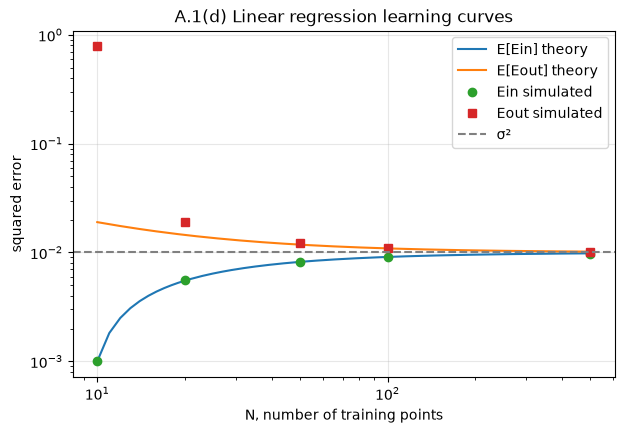

In [42]:
fig, ax = new_ax("N, number of training points", "squared error",
                 "A.1(d) Linear regression learning curves", logx=True, logy=True)
ax.plot(N_grid, Ein_th, "-",  label="E[Ein] theory")
ax.plot(N_grid, Eout_th, "-", label="E[Eout] theory")
ax.plot(Ns, Ein_avg, "o",  label="Ein simulated")
ax.plot(Ns, Eout_avg, "s", label="Eout simulated")
ax.axhline(sigma**2, ls="--", c="gray", label="σ²")
ax.legend(); fig.savefig("A1d.png", dpi=150)

B.1 Gradient descent on a non-linear surface

$E(u,v) = e^u + e^{2v} + e^{uv} + u^2 - 2uv + 2v^2 - 3u - 2v$

Gradient used in the code, from B.1(a):

$\partial E/\partial u = e^u + v\,e^{uv} + 2u - 2v - 3$

$\partial E/\partial v = 2e^{2v} + u\,e^{uv} - 2u + 4v - 2$

B.1(c) Gradient descent for three learning rates

In [43]:
def E(u, v):
    return np.exp(u) + np.exp(2 * v) + np.exp(u * v) + u**2 - 2 * u * v + 2 * v**2 - 3 * u - 2 * v

def grad_E(u, v):
    dE_du = np.exp(u) + v * np.exp(u * v) + 2 * u - 2 * v - 3
    dE_dv = 2 * np.exp(2 * v) + u * np.exp(u * v) - 2 * u + 4 * v - 2
    return np.array([dE_du, dE_dv])

def gd(eta, T=50, start=(0.0, 0.0)):
    """Run T steps of p <- p - eta * grad E(p). Returns the path (T+1, 2) and E along it."""
    p = np.array(start, dtype=float)
    path, errs = [p.copy()], [E(*p)]
    for t in range(T):
        p = p - eta * grad_E(*p)
        path.append(p.copy())
        errs.append(E(*p))
    return np.array(path), np.array(errs)

etas = [0.01, 0.1, 0.25]
runs = {eta: gd(eta) for eta in etas}

Check against the hand computation in B.1(b): the first two steps with η = 0.1.

In [44]:
path, errs = runs[0.1]
check = pd.DataFrame({
    "step": [0, 1, 2],
    "u": path[:3, 0],
    "v": path[:3, 1],
    "E(u, v)": errs[:3],
})
check.round(4)

,step,u,v,"E(u, v)"
0,0,0.0000,0.00,3.0000
1,1,0.2000,0.00,2.6614
2,2,0.3379,0.02,2.4974


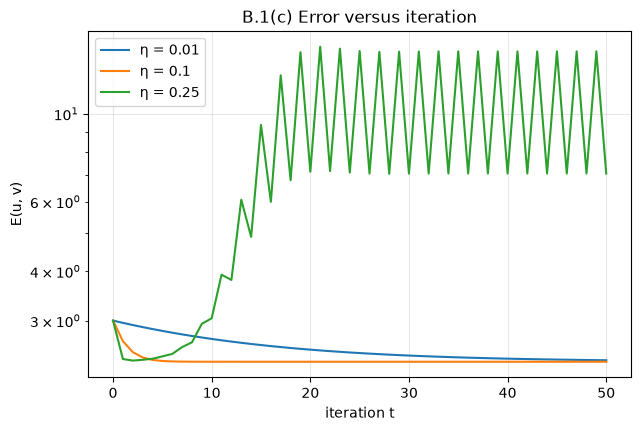

In [45]:
fig, ax = new_ax("iteration t", "E(u, v)", "B.1(c) Error versus iteration", logy=True)
for eta, (path, errs) in runs.items():
    ax.plot(errs, label=f"η = {eta}")
ax.legend(); fig.savefig("B1c_error.png", dpi=150)

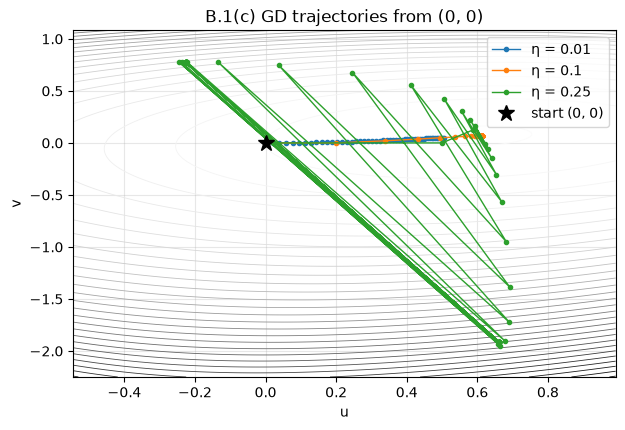

In [46]:
all_pts = np.vstack([path for path, _ in runs.values()])
pad = 0.3
u_lo, u_hi = all_pts[:, 0].min() - pad, all_pts[:, 0].max() + pad
v_lo, v_hi = all_pts[:, 1].min() - pad, all_pts[:, 1].max() + pad
U, V = np.meshgrid(np.linspace(u_lo, u_hi, 300), np.linspace(v_lo, v_hi, 300))

fig, ax = new_ax("u", "v", "B.1(c) GD trajectories from (0, 0)")
cs = ax.contour(U, V, E(U, V), levels=30, cmap="Greys", linewidths=0.6)
for eta, (path, errs) in runs.items():
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1, label=f"η = {eta}")
ax.plot(0, 0, "k*", ms=12, label="start (0, 0)")
ax.legend(); fig.savefig("B1c_paths.png", dpi=150)

B.1(d) Which η reaches the smallest E after 50 iterations?

In [47]:
summary = pd.DataFrame({
    "eta": etas,
    "u_50": [runs[e][0][-1, 0] for e in etas],
    "v_50": [runs[e][0][-1, 1] for e in etas],
    "E_50": [runs[e][1][-1] for e in etas],
    "E decreases every step": [bool(np.all(np.diff(runs[e][1]) <= 1e-12)) for e in etas],  # tolerance for float noise after convergence
    "|E_50 - E_49|": [abs(runs[e][1][-1] - runs[e][1][-2]) for e in etas],
})
print("Smallest E after 50 iterations: eta =", etas[int(summary["E_50"].argmin())])
summary.round(5)

Smallest E after 50 iterations: eta = 0.1


,eta,u_50,v_50,E_50,E decreases every step,|E_50 - E_49|
0,0.01,0.50610,0.05186,2.38170,True,0.00157
1,0.10,0.61181,0.07050,2.36082,True,0.00000
2,0.25,-0.22601,0.77350,7.06304,False,7.32272


η = 0.1 has the smallest E after 50 iterations. The largest η=0.25 jumps overa local minima again and again and is not able to reach it. The smallest η=0.01 reaches minima a lot longer and it takes more itarations for it to reach it, so η = 0.1 gets there a lot earlier, while η=0.01 is still not at 0 after 50 iterations.

C.2 Experiment: the regularization path

In [48]:
DEGREE = 10
NOISE_STD = 0.2

def make_sin_data(N, rng):
    """x ~ Uniform[-1, 1], y = sin(pi x) + noise with std 0.2."""
    x = rng.uniform(-1, 1, N)
    y = np.sin(np.pi * x) + NOISE_STD * rng.standard_normal(N)
    return x, y

def poly_raw(x, degree=DEGREE):
    """Columns x^1, ..., x^degree. The constant column is added after scaling."""
    return np.column_stack([x ** k for k in range(1, degree + 1)])

def fit_scaler(x):
    """Mean and std of each polynomial column, computed on TRAINING inputs only."""
    P = poly_raw(x)
    return P.mean(axis=0), P.std(axis=0)

def features(x, scaler):
    """z = (1, standardized x, ..., standardized x^10). 
    The constant 1 is not standardized, because its std is 0."""
    mu, sd = scaler
    return add_bias((poly_raw(x) - mu) / sd)

def ridge(Z, y, lam):
    """w_reg = (Z^T Z + lam I)^(-1) Z^T y, from C.1(b). 
    np.linalg.solve is more accurate than forming the inverse explicitly."""
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

In [49]:
rng = np.random.default_rng(SEED)
N, N_test = 30, 2000
x_tr, y_tr = make_sin_data(N, rng)
x_te, y_te = make_sin_data(N_test, rng)

scaler = fit_scaler(x_tr) # training statistics only
Z_tr, Z_te = features(x_tr, scaler), features(x_te, scaler)
print("Z_tr shape:", Z_tr.shape, " Z_te shape:", Z_te.shape)

Z_tr shape: (30, 11)  Z_te shape: (2000, 11)


---

C.2(a) Ein, Etest and ‖w_reg‖ along the path

In [50]:
log_lams = np.arange(2, -11, -1)      
rows = []
for ll in log_lams:
    w = ridge(Z_tr, y_tr, 10.0 ** ll)
    rows.append({
        "log10 lambda": ll,
        "E_in": mse(y_tr, Z_tr @ w),
        "E_test": mse(y_te, Z_te @ w),
        "||w_reg||": np.linalg.norm(w),
    })
path_df = pd.DataFrame(rows)
path_df.style.format({"E_in": "{:.5f}", "E_test": "{:.5f}", "||w_reg||": "{:.3f}"})

,log10 lambda,E_in,E_test,||w_reg||
0,2,0.37547,0.42906,0.113
1,1,0.19521,0.21179,0.489
2,0,0.06968,0.07287,1.218
3,-1,0.02781,0.04919,2.250
4,-2,0.01616,0.05077,4.102
5,-3,0.01379,0.05503,5.911
6,-4,0.01228,0.05714,15.734
7,-5,0.01045,0.06246,44.182
8,-6,0.01026,0.06593,55.585
9,-7,0.01026,0.06645,57.072


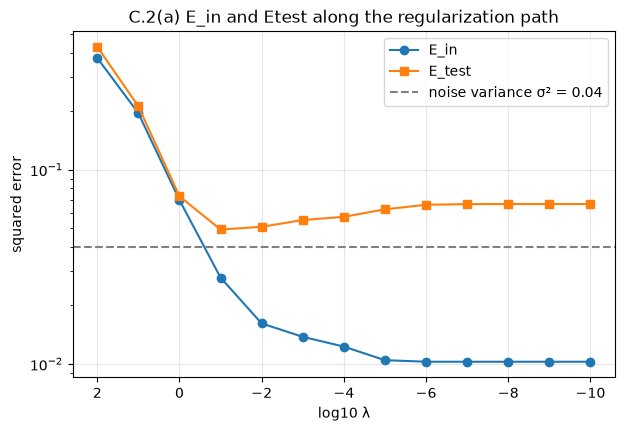

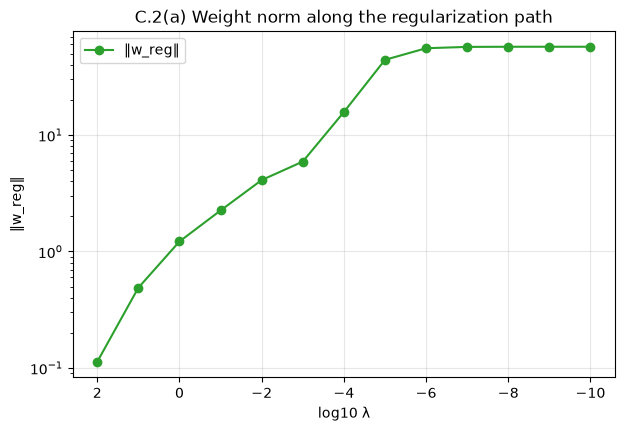

In [51]:
fig, ax = new_ax("log10 λ", "squared error", "C.2(a) E_in and Etest along the regularization path", logy=True)
ax.plot(path_df["log10 lambda"], path_df["E_in"], "o-", label="E_in")
ax.plot(path_df["log10 lambda"], path_df["E_test"], "s-", label="E_test")
ax.axhline(NOISE_STD**2, ls="--", c="gray", label="noise variance σ² = 0.04")
ax.invert_xaxis() # left = strong regularization, right = weak
ax.legend(); fig.savefig("C2a_errors.png", dpi=150)

fig, ax = new_ax("log10 λ", "‖w_reg‖", "C.2(a) Weight norm along the regularization path", logy=True)
ax.plot(path_df["log10 lambda"], path_df["||w_reg||"], "o-", c="C2", label="‖w_reg‖")
ax.invert_xaxis()
ax.legend(); fig.savefig("C2a_norm.png", dpi=150)

---

C.2(b) Best λ and the three regions

In [52]:
best = path_df.loc[path_df["E_test"].idxmin()]
print(f"Smallest E_test = {best['E_test']:.5f} at log10 lambda = {int(best['log10 lambda'])}")

Smallest E_test = 0.04919 at log10 lambda = -1


log10 λ = -1 gives the smallest E_test, and a bit lower E_in

log10 λ in [-2, 0] are over-regularized, the wights are pushed toward 0, and model becomes too simple, keeping bot E_in and E_test high, and close to each other, and ‖w‖ is small

log10 λ in [-2, -10] is under-regularized, E_in keeps falling but E_test rises, and ‖w‖ grows, meaning that polynomial is fitting the noise. 

---

C.2(c) Fitted curves for log10 λ ∈ {2, −3, −10}

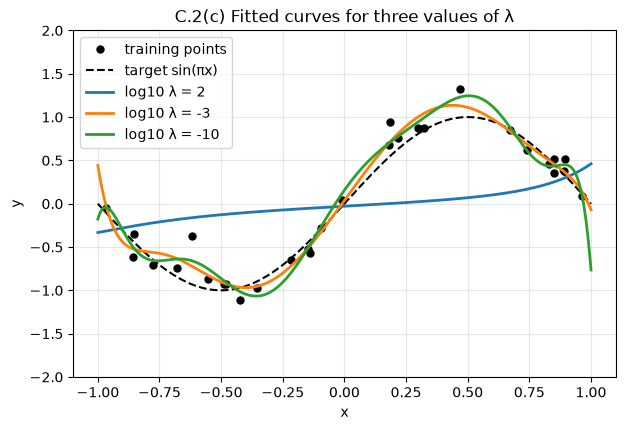

In [53]:
x_plot = np.linspace(-1, 1, 500)
Z_plot = features(x_plot, scaler)

fig, ax = new_ax("x", "y", "C.2(c) Fitted curves for three values of λ")
ax.plot(x_tr, y_tr, "ko", ms=5, label="training points")
ax.plot(x_plot, np.sin(np.pi * x_plot), "k--", lw=1.5, label="target sin(πx)")
for ll in [2, -3, -10]:
    w = ridge(Z_tr, y_tr, 10.0 ** ll)
    ax.plot(x_plot, Z_plot @ w, lw=2, label=f"log10 λ = {ll}")
ax.set_ylim(-2, 2)
ax.legend(); fig.savefig("C2c_fits.png", dpi=150)

log10 λ = 2 is underfitted and looks nearly flat, log10 λ = -10 is weaving around each point which corresponds to overfitting


D.1 Leave-one-out cross-validation

Points (-1, 0), (p, 1), (1, 0).

Constant model $h_0(x) = b_0$ (degree 0) and linear model $h_1(x) = a_1 x + b_1$ (degree 1), fitted by least squares, squared error.

---

D.1(c) `loocv(points, degree)`

In [54]:
def loocv(points, degree):
    """Leave-one-out error for polynomial regression of the given degree.
    For each point: fit np.polyfit on the other points, predict the left-out
    point, square the error. Return the average."""
    pts = np.asarray(points, dtype=float)
    errs = []
    for n in range(len(pts)):
        rest = np.delete(pts, n, axis=0)
        coef = np.polyfit(rest[:, 0], rest[:, 1], degree)
        pred = np.polyval(coef, pts[n, 0])
        errs.append((pts[n, 1] - pred) ** 2)
    return np.mean(errs), errs

def points_for(rho):
    return [(-1.0, 0.0), (rho, 1.0), (1.0, 0.0)]

Check against the hand answers from D.1(a) and D.1(b), with ρ = 2.

In [55]:
rows = []
for deg, name in [(0, "h0 constant"), (1, "h1 linear")]:
    e_cv, e_each = loocv(points_for(2.0), deg)
    rows.append({"model": name,
                 "e1 (leave out x=-1)": e_each[0],
                 "e2 (leave out x=rho)": e_each[1],
                 "e3 (leave out x=1)": e_each[2],
                 "Ecv": e_cv})
pd.DataFrame(rows).round(4)

,model,e1 (leave out x=-1),e2 (leave out x=rho),e3 (leave out x=1),Ecv
0,h0 constant,0.25,1.0,0.2500,0.5000
1,h1 linear,4.00,1.0,0.4444,1.8148


---

D.1(d) Sweep ρ over [1.1, 6]

In [56]:
rhos = np.round(np.arange(1.1, 6.0 + 1e-9, 0.01), 2)
E0 = np.array([loocv(points_for(r), 0)[0] for r in rhos])
E1 = np.array([loocv(points_for(r), 1)[0] for r in rhos])

# crossing = where the sign of E0 - E1 changes
diff = E0 - E1
idx = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]
# linear interpolation between the two grid points around each sign change
crossings = [rhos[i] - diff[i] * (rhos[i + 1] - rhos[i]) / (diff[i + 1] - diff[i]) for i in idx]
rho_exact = np.sqrt(9 + 4 * np.sqrt(6))
print("crossing(s) read from the sweep:", [round(c, 3) for c in crossings])
print(f"exact crossing sqrt(9 + 4 sqrt 6) = {rho_exact:.4f}")

crossing(s) read from the sweep: [np.float64(4.336)]
exact crossing sqrt(9 + 4 sqrt 6) = 4.3357


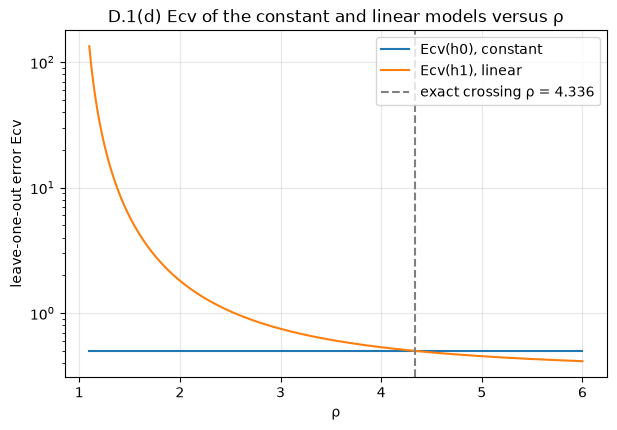

In [57]:
fig, ax = new_ax("ρ", "leave-one-out error Ecv", "D.1(d) Ecv of the constant and linear models versus ρ", logy=True)
ax.plot(rhos, E0, label="Ecv(h0), constant")
ax.plot(rhos, E1, label="Ecv(h1), linear")
ax.axvline(rho_exact, ls="--", c="gray", label=f"exact crossing ρ = {rho_exact:.3f}")
ax.legend(); fig.savefig("D1d_sweep.png", dpi=150)

In [58]:
# which model leave-one-out selects on each side of the crossing
for r in [2.0, 4.0, 4.5, 6.0]:
    e0, e1 = loocv(points_for(r), 0)[0], loocv(points_for(r), 1)[0]
    print(f"rho = {r}: Ecv(h0) = {e0:.4f}, Ecv(h1) = {e1:.4f} -> selects {'h0' if e0 < e1 else 'h1'}")

rho = 2.0: Ecv(h0) = 0.5000, Ecv(h1) = 1.8148 -> selects h0
rho = 4.0: Ecv(h0) = 0.5000, Ecv(h1) = 0.5348 -> selects h0
rho = 4.5: Ecv(h0) = 0.5000, Ecv(h1) = 0.4863 -> selects h1
rho = 6.0: Ecv(h0) = 0.5000, Ecv(h1) = 0.4139 -> selects h1


D.2 Experiment: choosing λ by cross-validation

Same process as C.2 with N = 200 training points (seed 407), test set of 2000 points, 

candidates $\log_{10}\lambda \in \{0, -2, -4, -6, -8\}$, 

5-fold CV with 40 points per fold.

In [59]:
DEGREE = 10
NOISE_STD = 0.2

def make_sin_data(N, rng):
    """x ~ Uniform[-1, 1], y = sin(pi x) + noise with std 0.2."""
    x = rng.uniform(-1, 1, N)
    y = np.sin(np.pi * x) + NOISE_STD * rng.standard_normal(N)
    return x, y

def poly_raw(x, degree=DEGREE):
    """Columns x^1, ..., x^degree. The constant column is added after scaling."""
    return np.column_stack([x ** k for k in range(1, degree + 1)])

def fit_scaler(x):
    """Mean and std of each polynomial column, computed on TRAINING inputs only."""
    P = poly_raw(x)
    return P.mean(axis=0), P.std(axis=0)

def features(x, scaler):
    """z = (1, standardized x, ..., standardized x^10). The constant 1 is not
    standardized, because its std is 0."""
    mu, sd = scaler
    return add_bias((poly_raw(x) - mu) / sd)

def ridge(Z, y, lam):
    """w_reg = (Z^T Z + lam I)^(-1) Z^T y, from C.1(b). np.linalg.solve is more
    accurate than forming the inverse explicitly."""
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

In [60]:
rng = np.random.default_rng(SEED)
N, N_test = 200, 2000
x_tr, y_tr = make_sin_data(N, rng)
x_te, y_te = make_sin_data(N_test, rng)

log_lams = [0, -2, -4, -6, -8]

def cv_error(x, y, lam, kfold):
    """Average validation MSE over the folds. Scaling uses the training folds only."""
    errs = []
    for tr_idx, va_idx in kfold.split(x):
        sc = fit_scaler(x[tr_idx])
        w = ridge(features(x[tr_idx], sc), y[tr_idx], lam)
        errs.append(mse(y[va_idx], features(x[va_idx], sc) @ w))
    return np.mean(errs)

def test_error(lam):
    """Train on all 200 points, evaluate on the 2000-point test set."""
    sc = fit_scaler(x_tr)
    w = ridge(features(x_tr, sc), y_tr, lam)
    return mse(y_te, features(x_te, sc) @ w)

D.2(a) 5-fold Ecv and Etest

In [61]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
print("fold sizes:", [len(va) for _, va in kf.split(x_tr)])

cv_df = pd.DataFrame({
    "log10 lambda": log_lams,
    "Ecv": [cv_error(x_tr, y_tr, 10.0 ** ll, kf) for ll in log_lams],
    "Etest": [test_error(10.0 ** ll) for ll in log_lams],
})
cv_df.style.format({"Ecv": "{:.5f}", "Etest": "{:.5f}"})

fold sizes: [40, 40, 40, 40, 40]


,log10 lambda,Ecv,Etest
0,0,0.04277,0.04434
1,-2,0.03928,0.04203
2,-4,0.04362,0.04218
3,-6,0.04526,0.04228
4,-8,0.04528,0.04228


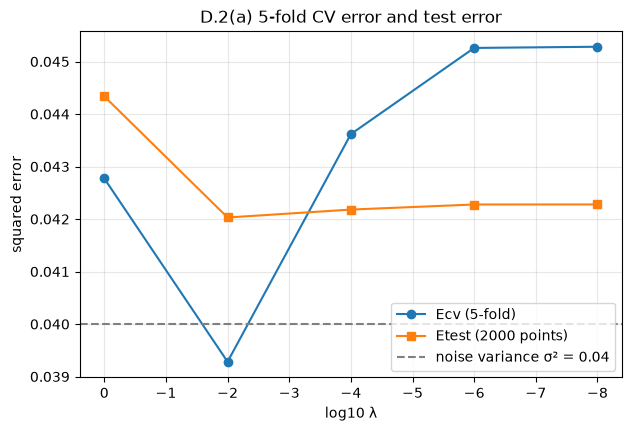

In [62]:
fig, ax = new_ax("log10 λ", "squared error", "D.2(a) 5-fold CV error and test error")
ax.plot(cv_df["log10 lambda"], cv_df["Ecv"], "o-", label="Ecv (5-fold)")
ax.plot(cv_df["log10 lambda"], cv_df["Etest"], "s-", label="Etest (2000 points)")
ax.axhline(NOISE_STD**2, ls="--", c="gray", label="noise variance σ² = 0.04")
ax.invert_xaxis()
ax.legend(); fig.savefig("D2a_cv.png", dpi=150)

D.2(b) λ selected by CV versus λ that minimizes Etest

In [63]:
ll_cv = int(cv_df.loc[cv_df["Ecv"].idxmin(), "log10 lambda"])
ll_test = int(cv_df.loc[cv_df["Etest"].idxmin(), "log10 lambda"])
print(f"CV selects log10 lambda = {ll_cv}")
print(f"Etest is smallest at log10 lambda = {ll_test}")
print("Same choice:", ll_cv == ll_test)

CV selects log10 lambda = -2
Etest is smallest at log10 lambda = -2
Same choice: True


D.2(c) 20 different shuffles

In [64]:
n_shuffles = 20
choices, all_cv = [], []
for s in range(n_shuffles):
    kf_s = KFold(n_splits=5, shuffle=True, random_state=SEED + s)
    ecv = [cv_error(x_tr, y_tr, 10.0 ** ll, kf_s) for ll in log_lams]
    all_cv.append(ecv)
    choices.append(log_lams[int(np.argmin(ecv))])

counts = pd.Series(choices).value_counts().reindex(log_lams, fill_value=0)
sel_df = pd.DataFrame({"log10 lambda": log_lams, "times selected (of 20)": counts.values})
sel_df

,log10 lambda,times selected (of 20)
0,0,0
1,-2,19
2,-4,1
3,-6,0
4,-8,0


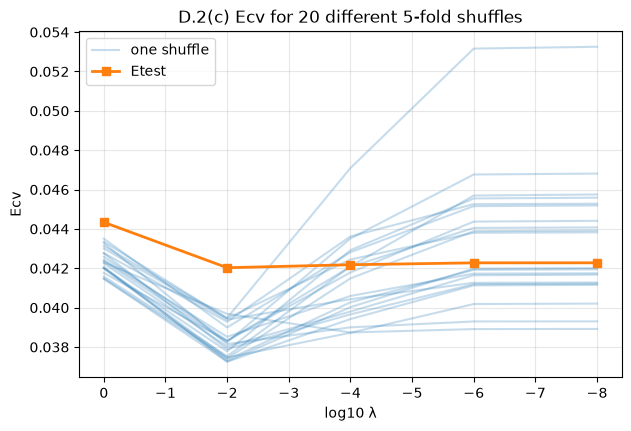

In [65]:
all_cv = np.array(all_cv)
fig, ax = new_ax("log10 λ", "Ecv", "D.2(c) Ecv for 20 different 5-fold shuffles")
for s in range(n_shuffles):
    ax.plot(log_lams, all_cv[s], "-", c="C0", alpha=0.25, label="one shuffle" if s == 0 else None)
ax.plot(log_lams, cv_df["Etest"], "s-", c="C1", lw=2, label="Etest")
ax.invert_xaxis()
ax.legend(); fig.savefig("D2c_shuffles.png", dpi=150)

λ = 10^-2 is selected in 19 of the 20 shuffles, and λ = 10^-4 in 1. So for these candidates a single 5-fold run is fairly reliable. 

Still, the E_cv of one candidate changes a lot from shuffle to shuffle: for λ = 10^-4 it ranges from 0.0387 to 0.0471. When two candidates are close, the selected λ can depend on how the data was shuffled.

E.2 Experiment: the Gaussian kernel

make_moons(n_samples=300, noise=0.3, random_state=407), 100 points held out as the test set, SVC with the RBF kernel 

$K(x,x') = \exp(-\gamma\|x-x'\|^2)$ 

and fixed C = 0.1. Errors are 0/1 errors (fraction misclassified).

In [66]:
X, y = make_moons(n_samples=300, noise=0.3, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=100, random_state=SEED)
print("train:", X_tr.shape, " test:", X_te.shape)

C = 0.1
gammas = [0.01, 0.1, 1, 10, 100, 1000]

def err01(model, X, y):
    return np.mean(model.predict(X) != y)

train: (200, 2)  test: (100, 2)


E.2(a) Ein, Etest and number of support vectors

In [67]:
models, rows = {}, []
for g in gammas:
    m = SVC(kernel="rbf", gamma=g, C=C).fit(X_tr, y_tr)
    models[g] = m
    rows.append({"gamma": g,
                 "Ein": err01(m, X_tr, y_tr),
                 "Etest": err01(m, X_te, y_te),
                 "# SV": int(m.n_support_.sum()),
                 "# SV with alpha = C (bounded)": int(np.sum(np.isclose(np.abs(m.dual_coef_), C)))})
gamma_df = pd.DataFrame(rows)
gamma_df.style.format({"Ein": "{:.3f}", "Etest": "{:.3f}"})

,gamma,Ein,Etest,# SV,# SV with alpha = C (bounded)
0,0.010000,0.485,0.530,194,194
1,0.100000,0.220,0.180,158,158
2,1.000000,0.135,0.140,136,126
3,10.000000,0.120,0.090,196,185
4,100.000000,0.485,0.530,199,185
5,1000.000000,0.485,0.530,200,104


E.2(b) Decision boundaries for γ ∈ {0.1, 10, 1000}

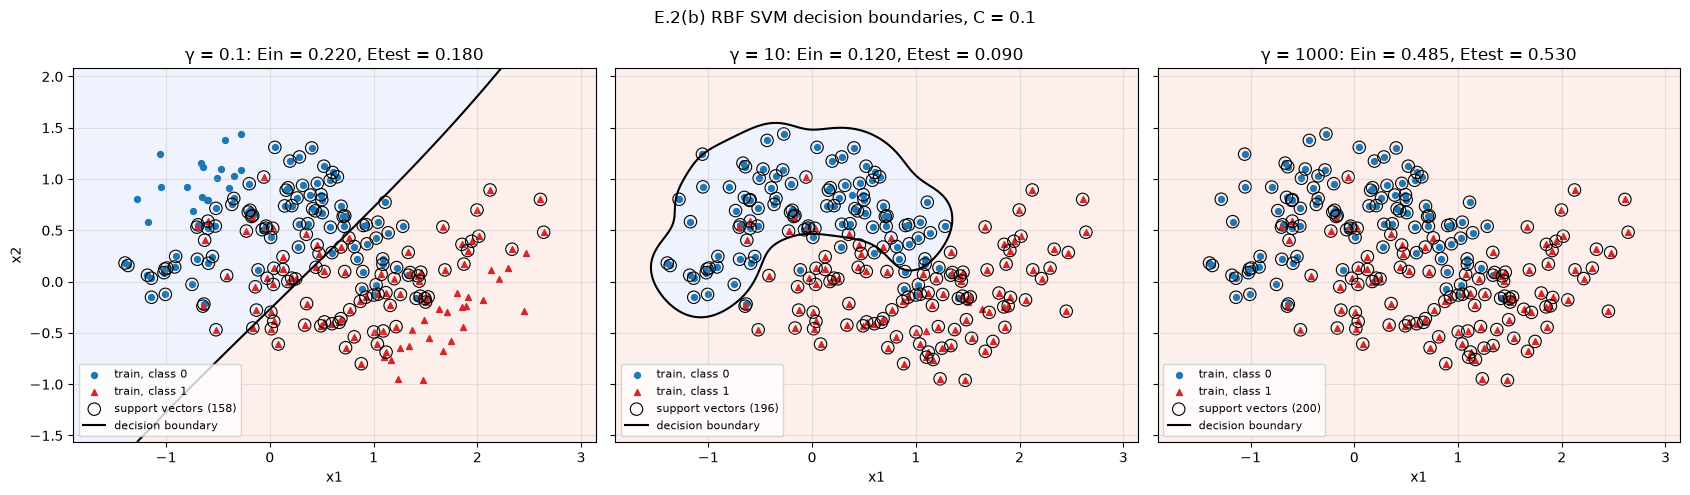

In [68]:
pad = 0.5
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 400),
                     np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, g in zip(axes, [0.1, 10, 1000]):
    m = models[g]
    f = m.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, f, levels=[0], colors="k", linewidths=1.5)
    for cls, mk, c in [(0, "o", "C0"), (1, "^", "C3")]:
        ax.scatter(*X_tr[y_tr == cls].T, marker=mk, c=c, s=18, label=f"train, class {cls}")
    sv = m.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=80, facecolors="none", edgecolors="k",
               linewidths=0.8, label=f"support vectors ({len(sv)})")
    ax.plot([], [], "k-", label="decision boundary")
    ax.set_title(f"γ = {g}: Ein = {err01(m, X_tr, y_tr):.3f}, Etest = {err01(m, X_te, y_te):.3f}")
    ax.set_xlabel("x1"); ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("x2")
fig.suptitle("E.2(b) RBF SVM decision boundaries, C = 0.1")
fig.tight_layout(); fig.savefig("E2b_boundaries.png", dpi=150)

E.2(c) Selecting γ by 5-fold cross-validation on the 200 training points

In [69]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_err01(g):
    errs = []
    for tr_idx, va_idx in kf.split(X_tr):
        m = SVC(kernel="rbf", gamma=g, C=C).fit(X_tr[tr_idx], y_tr[tr_idx])
        errs.append(err01(m, X_tr[va_idx], y_tr[va_idx]))
    return np.mean(errs)

gamma_df["Ecv (5-fold)"] = [cv_err01(g) for g in gammas]
g_cv = gamma_df.loc[gamma_df["Ecv (5-fold)"].idxmin(), "gamma"]
best_test = gamma_df["Etest"].min()
g_test_all = gamma_df.loc[np.isclose(gamma_df["Etest"], best_test), "gamma"].tolist()
print(f"CV selects gamma = {g_cv}")
print(f"Smallest Etest = {best_test:.3f}, reached by gamma in {g_test_all}")
print("Agree:", g_cv in g_test_all)
gamma_df[["gamma", "Ein", "Ecv (5-fold)", "Etest"]].style.format(
    {"Ein": "{:.3f}", "Ecv (5-fold)": "{:.3f}", "Etest": "{:.3f}"})

CV selects gamma = 1.0
Smallest Etest = 0.090, reached by gamma in [10.0]
Agree: False


,gamma,Ein,Ecv (5-fold),Etest
0,0.010000,0.485,0.495,0.530
1,0.100000,0.220,0.225,0.180
2,1.000000,0.135,0.135,0.140
3,10.000000,0.120,0.230,0.090
4,100.000000,0.485,0.505,0.530
5,1000.000000,0.485,0.520,0.530


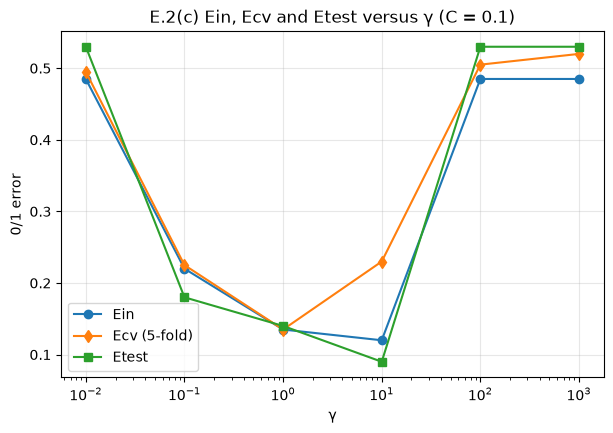

In [70]:
fig, ax = new_ax("γ", "0/1 error", "E.2(c) Ein, Ecv and Etest versus γ (C = 0.1)", logx=True)
ax.plot(gamma_df["gamma"], gamma_df["Ein"], "o-", label="Ein")
ax.plot(gamma_df["gamma"], gamma_df["Ecv (5-fold)"], "d-", label="Ecv (5-fold)")
ax.plot(gamma_df["gamma"], gamma_df["Etest"], "s-", label="Etest")
ax.legend(); fig.savefig("E2c_cv.png", dpi=150)

In [71]:
rows = []
for g in [1, 10, 100, 1000]:
    for C_big in [0.1, 1000]:
        m = SVC(kernel="rbf", gamma=g, C=C_big).fit(X_tr, y_tr)
        rows.append({"gamma": g, "C": C_big, "Ein": err01(m, X_tr, y_tr), "Etest": err01(m, X_te, y_te),
                     "# SV": int(m.n_support_.sum())})
pd.DataFrame(rows).style.format({"Ein": "{:.3f}", "Etest": "{:.3f}"})

,gamma,C,Ein,Etest,# SV
0,1,0.100000,0.135,0.140,136
1,1,1000.000000,0.105,0.090,59
2,10,0.100000,0.120,0.090,196
3,10,1000.000000,0.020,0.210,56
4,100,0.100000,0.485,0.530,199
5,100,1000.000000,0.000,0.240,184
6,1000,0.100000,0.485,0.530,200
7,1000,1000.000000,0.000,0.430,200


E.2(e) Numerical check: $\tilde K = pK + q$ with p = 3, q = 5

In [72]:
p, q = 3.0, 5.0
rows = []
for g in gammas:
    base = models[g]
    K_tr = p * rbf_kernel(X_tr, X_tr, gamma=g) + q
    K_te = p * rbf_kernel(X_te, X_tr, gamma=g) + q
    for name, C_tilde in [("C/p", C / p), ("pC", p * C)]:
        m = SVC(kernel="precomputed", C=C_tilde).fit(K_tr, y_tr)
        rows.append({
            "gamma": g,
            "C_tilde": name,
            "same test predictions": f"{np.mean(m.predict(K_te) == base.predict(X_te)):.0%}",
            "max |decision diff|": np.max(np.abs(m.decision_function(K_te) - base.decision_function(X_te))),
        })
check_df = pd.DataFrame(rows)
check_df.style.format({"max |decision diff|": "{:.2e}"})

,gamma,C_tilde,same test predictions,max |decision diff|
0,0.010000,C/p,100%,1.99e-09
1,0.010000,pC,47%,1.78e+00
2,0.100000,C/p,100%,1.19e-08
3,0.100000,pC,97%,1.06e+00
4,1.000000,C/p,100%,1.03e-07
5,1.000000,pC,94%,8.57e-01
6,10.000000,C/p,100%,2.97e-07
7,10.000000,pC,95%,8.79e-01
8,100.000000,C/p,100%,2.01e-04
9,100.000000,pC,62%,1.63e+00
